# Artworks {#sec-artworks}

This chapter is a Jupyter notebook. It queries the CPS Wikibase for all items of type *artwork* (Q1) and shows how the data layer of this book works.

## Querying the CPS Wikibase

The function `cps.artworks()` sends a SPARQL query (`src/baldessari/queries/works.rq`) to the CPS endpoint and returns the result as a pandas `DataFrame`.

In [1]:
#| echo: true
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd() / "src"))

from baldessari import cps, plots, table, works_table

artworks = cps.artworks()
artworks.shape

(73, 20)

## All artworks

In [2]:
#| label: tbl-artworks
#| tbl-cap: "Artworks in the CPS Wikibase."
table(works_table(artworks))

ID,Title,Year,Materials,Size (cm)
Q89,Installation photograph of Lamp,,,
Q90,Installation photograph of Plant,,,
Q50,"Duck Pond Bar, National City, California",1967.0,canvas; acrylic paint; photoemulsion,152 × 170
Q99,Isocephaly,1968.0,color,
Q102,What To Leave Out,1968.0,color,
Q111,Black Curtain,1970.0,sound; black-and-white,
Q109,Black Painting,1970.0,sound; black-and-white,
Q103,Cremation,1970.0,sound; black-and-white,
Q107,Folding Hat,1970.0,sound; black-and-white,
Q106,Folding Hat: Version 1,1970.0,sound; black-and-white,


## Artworks over time

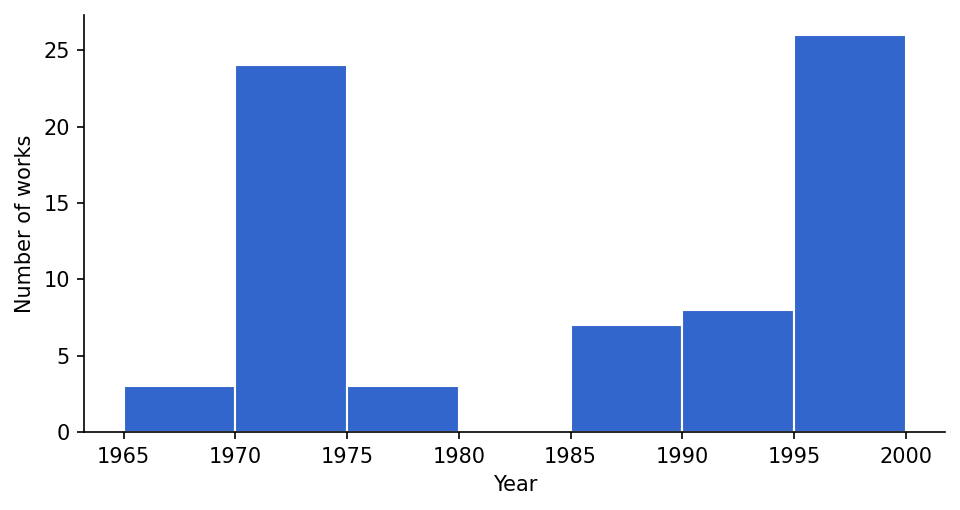

In [3]:
#| label: fig-artworks-per-year
#| fig-cap: "Artworks by year of creation (five-year bins)."
plots.per_year(artworks)

@fig-artworks-per-year includes only the works with a recorded date of creation (P7).

## Object types as stated in the catalogue

The property *Object type (as stated)* (P37) keeps the wording of the source catalogue.

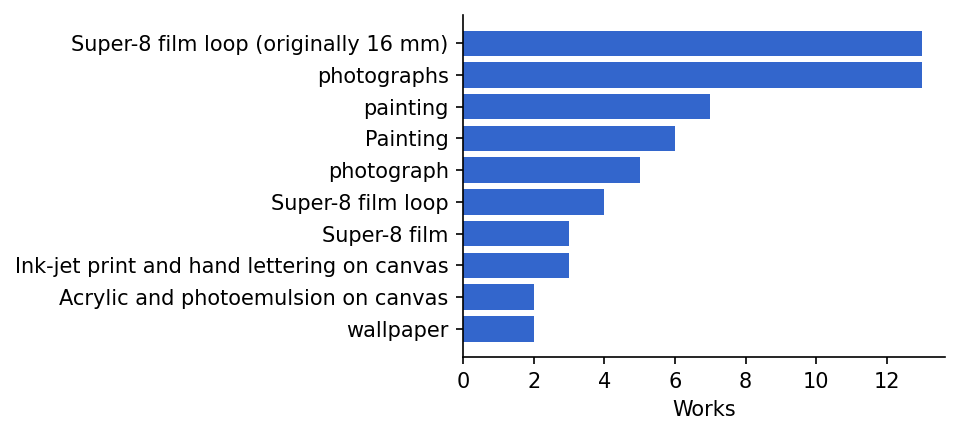

In [4]:
#| label: fig-object-types
#| fig-cap: "Most frequent object types as stated in the catalogue."
stated = (
    artworks["objectTypeStated"].dropna()
    .value_counts().head(10).rename_axis("Object type").reset_index(name="Works")
)
plots.bar_counts(stated, "Object type", "Works")